# 14 - Model assumptions, residual diagnostics and parameters

| | |
|---|---|
| **Milestone** | Milestone 2 |
| **Task** | M2-T6 (assumptions and diagnostics) |
| **Stage** | Stage 3 (forecasting) |
| **Aim** | For each classical model: state its assumptions, check them on the residuals (autocorrelation, Ljung-Box, normality, stationary and invertible roots), and list the fitted parameters with a one-line justification. |
| **Inputs** | `outputs/m2/tables/m2_sample_items.csv`<br>`outputs/m2/tables/classical_orders.csv`<br>`data/interim/{foods,hobbies,household}_candidates.csv` |
| **Outputs** | `outputs/m2/tables/diagnostics_items.csv`<br>`outputs/m2/tables/diagnostics_summary.csv`<br>`outputs/m2/tables/parameters_items.csv`<br>`outputs/m2/tables/parameters_summary.csv`<br>`outputs/m2/figures/m2_residual_acf.png`<br>`outputs/m2/figures/m2_diagnostics_pass.png` |
| **Hypotheses** | none tested; supports the model choice behind H1-H4 |
| **Expected runtime** | about 2-3 min |

## 1. Setup and config

Shared settings from `src/config.py`.

In [1]:
import os, sys, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ast import literal_eval
from joblib import Parallel, delayed
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from config import ROOT, INTERIM, M2_TABLES, M2_FIGS, ORIGINS, CATEGORIES, FIG_STYLE, NAMES, COLORS, make_dirs
import classical

make_dirs()
plt.rcParams.update(FIG_STYLE)
WRITTEN = []

## 2. Load data

The orders chosen in notebook 13, and each series up to origin 0 (the same data the orders were chosen on).

In [2]:
sample = pd.read_csv(M2_TABLES / "m2_sample_items.csv")
orders = pd.read_csv(M2_TABLES / "classical_orders.csv")
for c in ["sarima_order", "sarima_sorder", "arima_order"]:
    orders[c] = orders[c].apply(literal_eval)
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
o0 = ORIGINS[0]
hist = {i: g.loc[g["date"] <= o0, "sales"].to_numpy(dtype=float) for i, g in long_df.groupby("item_id") if i in set(sample["item_id"])}
for cat in CATEGORIES:
    hist[cat] = long_df[(long_df["category"] == cat) & (long_df["date"] <= o0)].groupby("date")["sales"].sum().to_numpy(dtype=float)
hist["CA_TOTAL"] = long_df[long_df["date"] <= o0].groupby("date")["sales"].sum().to_numpy(dtype=float)
print(len(hist), "series")

154 series


## 3. Method

| Model | Assumptions | How we check them |
|---|---|---|
| Holt-Winters additive | level, trend and a weekly pattern of fixed size explain the series; what is left is uncorrelated noise | Ljung-Box on residuals at lags 7 and 14; residual ACF |
| Holt-Winters multiplicative | as above, but the weekly pattern scales with the level; needs positive data | the swing rule in notebook 12; same residual checks; items use sales + 1 |
| Damped Holt-Winters (ETS) | as additive, with a trend that fades out | refitted at origin 0 (full history, as in notebook 02) only to check residuals |
| ARIMA(p,d,q) | after d differences the series is stationary; residuals are white noise; the fitted model is stationary and invertible | d from KPSS (`ndiffs`); Ljung-Box; AR and MA roots outside the unit circle |
| SARIMA(p,d,q)(P,D,Q)7 | as ARIMA, plus the weekly season is captured by seasonal terms | as ARIMA; D from OCSB (`nsdiffs`); seasonal roots too |
| All, for intervals | residuals are roughly normal with constant spread | Jarque-Bera; this matters for the textbook safety-stock formula, not for point forecasts |
| LightGBM | none about the error distribution; it only needs the features to be available at forecast time | the no-lookahead design of notebook 02 |

Residuals are taken from each model's fit at origin 0. The first 28 residuals are dropped, because state-space models start with large residuals while they settle.

## 4. Run

One fit per model per series at origin 0; tests on the residuals; parameters saved.

In [3]:
LAGS = [7, 14]

def tests(resid):
    """Ljung-Box (lags 7 and 14) and Jarque-Bera on one residual series."""
    r = np.asarray(resid, dtype=float)[28:]
    r = r[np.isfinite(r)]
    lb = acorr_ljungbox(r, lags=LAGS, return_df=True)["lb_pvalue"].to_numpy()
    jb = stats.jarque_bera(r).pvalue
    return {"lb_p7": lb[0], "lb_p14": lb[1], "jb_p": jb, "lb_pass": bool((lb > 0.05).all()), "jb_pass": bool(jb > 0.05)}

def diagnose(name, y_all, row):
    y = classical.last_days(y_all)
    out, params = [], []
    fits = {"sarima": lambda: classical.fit_sarima(y, row["sarima_order"], row["sarima_sorder"])[0],
            "arima": lambda: classical.fit_sarima(y, row["arima_order"])[0],
            "hw_add": lambda: classical.fit_hw(y, "add")[0],
            "hw_mul": lambda: classical.fit_hw(y, "mul")[0],
            "ets": lambda: classical.ExponentialSmoothing(y_all, trend="add", damped_trend=True, seasonal="add",
                                                         seasonal_periods=7, initialization_method="estimated").fit()}
    for model, fit in fits.items():
        try:
            res = fit()
        except Exception as e:
            out.append({"series": name, "model": model, "fit_failed": True})
            continue
        d = {"series": name, "model": model, "fit_failed": False, **tests(res.resid)}
        if model in ("sarima", "arima"):
            ar, ma = np.abs(getattr(res, "arroots", [])), np.abs(getattr(res, "maroots", []))
            d["stationary_invertible"] = bool((len(ar) == 0 or ar.min() > 1) and (len(ma) == 0 or ma.min() > 1))
            p = dict(zip(res.param_names, res.params))
        else:
            p = {k: res.params.get(k) for k in ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]}
        out.append(d)
        params.append({"series": name, "model": model, **{k: float(v) for k, v in p.items() if v is not None}})
    return out, params

o = orders.set_index("series")
res = Parallel(n_jobs=8)(delayed(diagnose)(name, y, o.loc[name]) for name, y in hist.items())
diag = pd.DataFrame([r for rows, _ in res for r in rows])
params = pd.DataFrame([p for _, ps in res for p in ps])
for c in ["lb_pass", "jb_pass", "stationary_invertible"]:     # yes/no with blanks (e.g. no roots for Holt-Winters)
    diag[c] = diag[c].astype(float)
diag["level"] = np.where(diag["series"].isin(CATEGORIES + ["CA_TOTAL"]), "aggregate", "item")
params["level"] = np.where(params["series"].isin(CATEGORIES + ["CA_TOTAL"]), "aggregate", "item")
diag.to_csv(M2_TABLES / "diagnostics_items.csv", index=False)
params.to_csv(M2_TABLES / "parameters_items.csv", index=False)
WRITTEN += [M2_TABLES / "diagnostics_items.csv", M2_TABLES / "parameters_items.csv"]
print(len(diag), "model fits checked")

770 model fits checked


## 5. Results

**Share of series that pass each check.**

In [4]:
summ = diag.groupby(["level", "model"]).agg(n=("series", "size"), fit_failed=("fit_failed", "mean"),
                                            ljung_box_pass=("lb_pass", "mean"), normality_pass=("jb_pass", "mean"),
                                            roots_ok=("stationary_invertible", "mean")).reset_index()
summ.to_csv(M2_TABLES / "diagnostics_summary.csv", index=False)
WRITTEN.append(M2_TABLES / "diagnostics_summary.csv")
print(summ.round(3).to_string(index=False))

    level  model   n  fit_failed  ljung_box_pass  normality_pass  roots_ok
aggregate  arima   4         0.0           0.000           0.000      1.00
aggregate    ets   4         0.0           0.000           0.000       NaN
aggregate hw_add   4         0.0           0.250           0.000       NaN
aggregate hw_mul   4         0.0           0.250           0.000       NaN
aggregate sarima   4         0.0           0.000           0.000      0.75
     item  arima 150         0.0           0.287           0.000      1.00
     item    ets 150         0.0           0.293           0.000       NaN
     item hw_add 150         0.0           0.473           0.007       NaN
     item hw_mul 150         0.0           0.487           0.007       NaN
     item sarima 150         0.0           0.820           0.007      1.00


**Parameter table.** Orders chosen, and the median fitted parameters across the 150 items (aggregates listed one by one).

In [5]:
items_orders = orders[orders["level"] == "item"]
print("Most common SARIMA orders (items):")
print(items_orders.apply(lambda r: f"{r['sarima_order']}{r['sarima_sorder'][:3]}", axis=1).value_counts().head(8).to_string())
print("\nMost common ARIMA orders (items):")
print(items_orders["arima_order"].astype(str).value_counts().head(5).to_string())
print(f"\nd: {items_orders['d'].value_counts().sort_index().to_dict()}   D: {items_orders['D'].value_counts().sort_index().to_dict()}")

keep = ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend", "intercept",
        "ar.L1", "ar.L2", "ma.L1", "ma.L2", "ar.S.L7", "ma.S.L7", "sigma2"]
p_items = params[params["level"] == "item"]
ps = p_items.groupby("model")[[k for k in keep if k in params]].median().T
ps.to_csv(M2_TABLES / "parameters_summary.csv")
WRITTEN.append(M2_TABLES / "parameters_summary.csv")
print("\nMedian fitted parameters (items; blank = not in that model):")
print(ps.round(3).to_string())
print("\nAggregates, SARIMA:")
print(orders[orders["level"] == "aggregate"][["series", "d", "D", "sarima_order", "sarima_sorder", "arima_order"]].to_string(index=False))

Most common SARIMA orders (items):
(1, 1, 2)(1, 0, 1)    32
(0, 1, 1)(1, 0, 1)    22
(1, 1, 1)(1, 0, 1)    17
(2, 1, 1)(1, 0, 1)    16
(0, 1, 2)(1, 0, 1)     8
(2, 1, 2)(1, 0, 1)     8
(0, 0, 0)(1, 0, 1)     6
(2, 0, 2)(1, 0, 1)     4

Most common ARIMA orders (items):
arima_order
(1, 1, 1)    29
(2, 1, 2)    26
(2, 1, 1)    24
(0, 1, 2)    16
(0, 1, 1)    14

d: {0: 29, 1: 121}   D: {0: 150}

Median fitted parameters (items; blank = not in that model):
model                arima    ets  hw_add  hw_mul  sarima
smoothing_level        NaN  0.096   0.072   0.077     NaN
smoothing_trend        NaN  0.000   0.000   0.000     NaN
smoothing_seasonal     NaN  0.000   0.000   0.000     NaN
damping_trend          NaN  0.921     NaN     NaN     NaN
intercept            4.200    NaN     NaN     NaN   0.119
ar.L1                0.311    NaN     NaN     NaN   0.229
ar.L2               -0.096    NaN     NaN     NaN   0.053
ma.L1               -0.949    NaN     NaN     NaN  -0.965
ma.L2               

**One-line justifications.**
* **Holt-Winters additive:** the item series are mostly stationary with a fixed-size weekly swing (notebook 12), which is what additive Holt-Winters assumes.
* **Holt-Winters multiplicative:** kept for totals, where the swing can scale with the level; on items it needs the +1 shift because of zero days.
* **Damped Holt-Winters (ETS):** a damped trend avoids running a short-term trend forward for 28 days.
* **ARIMA:** captures short-term autocorrelation; it is the non-seasonal reference that shows what the weekly terms add.
* **SARIMA:** adds weekly AR/MA terms; orders were chosen by AICc on data up to origin 0 only.

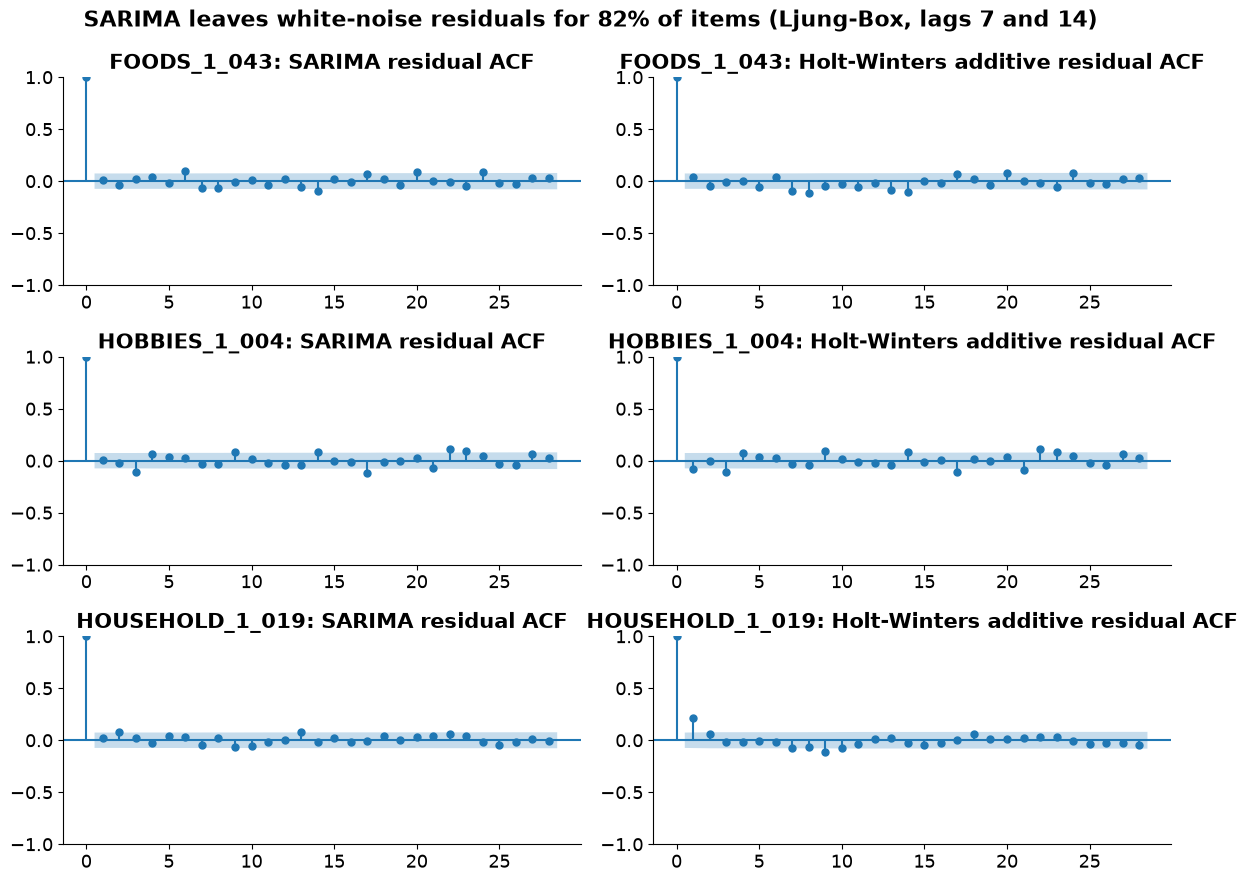

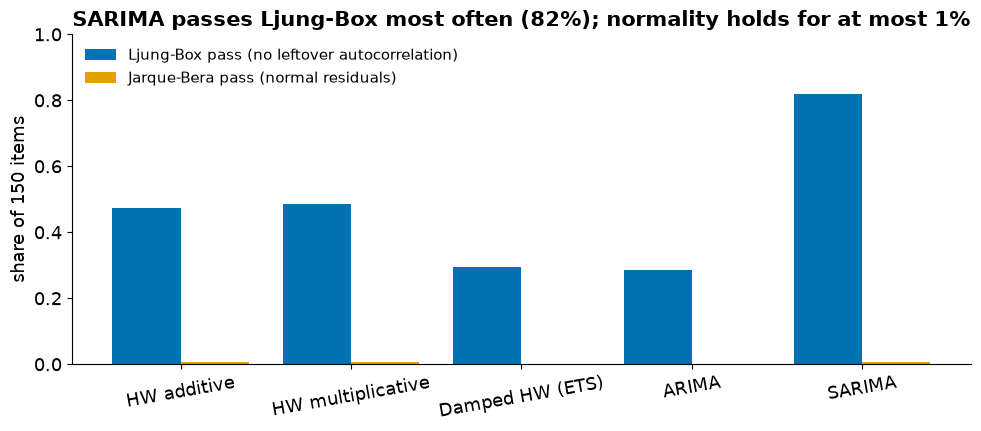

In [6]:
ex = sample.groupby("category")["item_id"].first().tolist()
fig, axes = plt.subplots(len(ex), 2, figsize=(12, 3 * len(ex)))
for row, item in zip(axes, ex):
    y = classical.last_days(hist[item])
    r = o.loc[item]
    for ax, (model, res) in zip(row, [("sarima", classical.fit_sarima(y, r["sarima_order"], r["sarima_sorder"])[0]),
                                      ("hw_add", classical.fit_hw(y, "add")[0])]):
        plot_acf(np.asarray(res.resid)[28:], lags=28, ax=ax, title=f"{item}: {NAMES[model]} residual ACF")
share = summ[(summ["level"] == "item") & (summ["model"] == "sarima")]["ljung_box_pass"].iloc[0]
fig.suptitle(f"SARIMA leaves white-noise residuals for {share:.0%} of items (Ljung-Box, lags 7 and 14)", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(M2_FIGS / "m2_residual_acf.png")
WRITTEN.append(M2_FIGS / "m2_residual_acf.png")
plt.show()

s = summ[summ["level"] == "item"].set_index("model").loc[["hw_add", "hw_mul", "ets", "arima", "sarima"]]
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(s))
ax.bar(x - 0.2, s["ljung_box_pass"], 0.4, color="#0072B2", label="Ljung-Box pass (no leftover autocorrelation)")
ax.bar(x + 0.2, s["normality_pass"], 0.4, color="#E69F00", label="Jarque-Bera pass (normal residuals)")
ax.set_xticks(x, [NAMES[m].replace("Holt-Winters ", "HW ") for m in s.index], rotation=10)
ax.set_ylim(0, 1)
ax.set_ylabel("share of 150 items")
best = s["ljung_box_pass"].idxmax()
ax.set_title(f"{NAMES[best]} passes Ljung-Box most often ({s.loc[best, 'ljung_box_pass']:.0%}); "
             f"normality holds for at most {s['normality_pass'].max():.0%}")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(M2_FIGS / "m2_diagnostics_pass.png")
WRITTEN.append(M2_FIGS / "m2_diagnostics_pass.png")
plt.show()

**Post-hoc check (not pre-registered): is SARIMA on the totals a model problem or a numerical one?**
Notebook 13 found SARIMA fits on the totals that diverged quietly (all-zero or far too large forecasts). The totals
run to thousands of units a day, and SARIMAX's optimiser can struggle with values that large. Here the same orders are
refitted on the totals **in thousands of units** (divide by 1,000, forecast, multiply back). This is a diagnostic only:
the pre-registered results in notebook 13 are not replaced.

In [7]:
from config import EVAL_ORIGINS, HORIZON
from metrics import mase_scale

rows = []
for cat in CATEGORIES + ["CA_TOTAL"]:
    s = long_df if cat == "CA_TOTAL" else long_df[long_df["category"] == cat]
    s = s.groupby("date")["sales"].sum()
    r = o.loc[cat]
    for origin in EVAL_ORIGINS:
        y = classical.last_days(s[s.index <= origin].to_numpy(dtype=float))
        act = s.reindex(pd.date_range(origin + pd.Timedelta(days=1), periods=HORIZON)).to_numpy()
        sc = mase_scale(s[s.index <= origin].to_numpy(dtype=float))
        for unit, k in [("units", 1.0), ("thousands", 1000.0)]:
            fc, ok, fb = classical.sarima_forecast(y / k, r["sarima_order"], r["sarima_sorder"], HORIZON)
            rows.append({"series": cat, "origin": origin, "scale": unit, "converged": ok, "fallback": fb,
                         "mase": np.mean(np.abs(act - fc * k)) / sc})
rescale = pd.DataFrame(rows)
rescale.to_csv(M2_TABLES / "sarima_totals_rescaled.csv", index=False)
WRITTEN.append(M2_TABLES / "sarima_totals_rescaled.csv")
print(rescale.groupby(["series", "scale"]).agg(mean_mase=("mase", "mean"), converged=("converged", "mean"),
                                               fallbacks=("fallback", "sum")).round(3).to_string())

                     mean_mase  converged  fallbacks
series    scale                                     
CA_TOTAL  thousands      0.864      0.167          0
          units          0.870      0.333          1
FOODS     thousands      0.834      0.167          0
          units          1.976      0.000          0
HOBBIES   thousands      0.699      0.500          0
          units          0.674      0.333          0
HOUSEHOLD thousands      0.928      0.000          0
          units          4.710      0.500          1


## 6. Checks

In [8]:
assert set(diag["model"]) == {"sarima", "arima", "hw_add", "hw_mul", "ets"}
assert diag.groupby("model")["series"].nunique().eq(len(hist)).all()
# orders used here are exactly the ones notebook 13 used
assert set(orders["series"]) == set(hist)
print("fit failures:", int(diag["fit_failed"].sum()), "of", len(diag))
print("all checks passed")

fit failures: 0 of 770
all checks passed


## 7. Interpretation

**We expected** SARIMA to leave the cleanest residuals and normality to fail for daily counts.
**We found:**
* Ljung-Box (no leftover autocorrelation at lags 7 and 14) passes for **82%** of items with SARIMA, 47-49% with Holt-Winters, 29% with ARIMA and damped Holt-Winters. The weekly AR/MA terms are what remove the remaining weekly correlation.
* Jarque-Bera normality passes for at most **0.7%** of items: daily sales are skewed counts. That does not hurt point forecasts, but it explains why the textbook safety-stock formula under-delivers (Milestone 1) and why notebook 16 also uses calibrated safety stock.
* Every fitted ARIMA/SARIMA on items is stationary and invertible; one of the four totals is not.
* Typical item orders: d = 1 (121 of 150), D = 0 (all), seasonal (1, 0, 1)₇ with a seasonal AR near 1 (median 0.996) and seasonal MA near −1 (−0.968): close to a seasonal difference, even though `nsdiffs` did not ask for one. Holt-Winters picks small level smoothing (about 0.07-0.10) and a fixed weekly pattern.
* **Post-hoc (not pre-registered):** refitting SARIMA on the totals in thousands of units removes the divergence (FOODS 1.976 → 0.834, HOUSEHOLD → 0.928). The same raw-unit fit also gives different answers in notebook 13 (fitted in joblib worker processes) and here (main process): HOUSEHOLD 1.145 vs 4.710. Each notebook repeats exactly when rerun, so these fits are sensitive to the numerical environment rather than random. The Milestone 2 numbers keep the pre-registered raw-unit fits.

## 8. What comes next

* Notebook **15** tests whether a shift-aware SARIMA helps (H3).
* Notebook **16** checks what these forecasts mean for stock.

In [9]:
# Files written by this notebook
for p in WRITTEN:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\m2\tables\diagnostics_items.csv 79 KB
outputs\m2\tables\parameters_items.csv 75 KB
outputs\m2\tables\diagnostics_summary.csv 1 KB
outputs\m2\tables\parameters_summary.csv 1 KB
outputs\m2\figures\m2_residual_acf.png 137 KB
outputs\m2\figures\m2_diagnostics_pass.png 65 KB
outputs\m2\tables\sarima_totals_rescaled.csv 3 KB
